# Lab 13-10 · Waveguides and Resonators

Companion to [chapter 13-10](../../chapters/13-10-waveguides-and-resonators.md). Four parts: TE mode patterns; the dispersion diagram and group delay of WR-90; a numerical eigen-solve of the guide's cross-section and below-cutoff attenuation; and the fibre's fundamental mode. Run the cells in order.

In [1]:
import math
import numpy as np
import matplotlib.pyplot as plt
import scipy.sparse as sps
import scipy.sparse.linalg as spla
from scipy.optimize import brentq
from scipy.special import jv, kv
c0 = 299792458.0
a, b = 0.02286, 0.01016

## Part 1 · Mode patterns

Plot $\lvert E_y\rvert$ of TE$_{10}$ and TE$_{20}$ and the transverse electric field magnitude of TE$_{11}$ over the guide's cross-section.

**Predict first:** where is the TE$_{10}$ field strongest, and where is it zero?

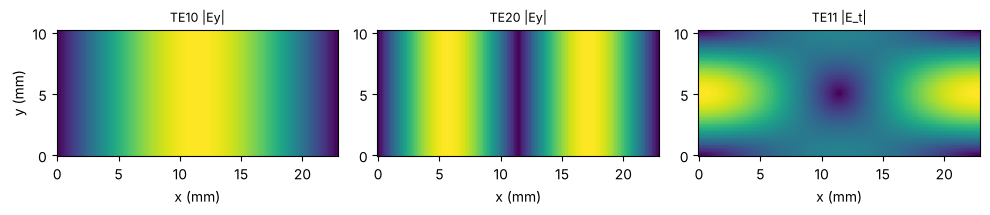

In [2]:
x = np.linspace(0, a, 200); y = np.linspace(0, b, 90); X, Y = np.meshgrid(x, y)
fields = {'TE10 |Ey|': np.abs(np.sin(np.pi * X / a)) * np.ones_like(Y),
          'TE20 |Ey|': np.abs(np.sin(2 * np.pi * X / a)) * np.ones_like(Y),
          'TE11 |E_t|': np.hypot(np.cos(np.pi * X / a) * np.sin(np.pi * Y / b) / b,
                                 np.sin(np.pi * X / a) * np.cos(np.pi * Y / b) / a)}
fig, axes = plt.subplots(1, 3, figsize=(10, 2.4))
for ax, (name, F) in zip(axes, fields.items()):
    ax.pcolormesh(X * 1e3, Y * 1e3, F / F.max(), shading='auto', rasterized=True); ax.set_title(name, fontsize=9)
    ax.set_aspect('equal'); ax.set_xlabel('x (mm)')
axes[0].set_ylabel('y (mm)'); plt.tight_layout(); plt.show()

## Part 2 · Dispersion and group delay

Plot β against frequency for TE$_{10}$ and the group delay of a 1 m run across the recommended band.

**Predict first:** how much more delay does 8.2 GHz see than 12.4 GHz over 1 m?

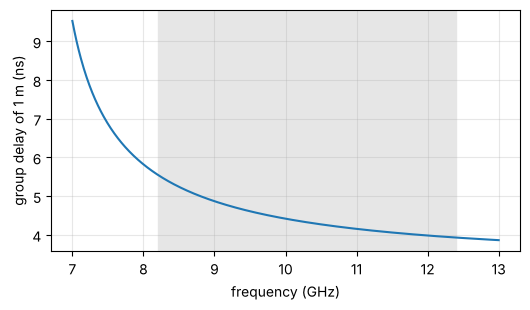

delay over 1 m: 5.555 ns at 8.2 GHz, 3.930 ns at 12.4 GHz, difference 1.625 ns


In [3]:
fc = c0 / (2 * a)
f = np.linspace(7e9, 13e9, 600)
vg = c0 * np.sqrt(1 - (fc / f) ** 2)
tau = 1 / vg
fig, ax = plt.subplots(figsize=(5.4, 3.2))
ax.plot(f / 1e9, tau * 1e9); ax.axvspan(8.2, 12.4, color='0.9')
ax.set_xlabel('frequency (GHz)'); ax.set_ylabel('group delay of 1 m (ns)'); ax.grid(alpha=0.3)
plt.tight_layout(); plt.show()
t_lo, t_hi = 1 / (c0 * math.sqrt(1 - (fc / 8.2e9) ** 2)), 1 / (c0 * math.sqrt(1 - (fc / 12.4e9) ** 2))
print(f"delay over 1 m: {t_lo * 1e9:.3f} ns at 8.2 GHz, {t_hi * 1e9:.3f} ns at 12.4 GHz, difference {(t_lo - t_hi) * 1e9:.3f} ns")

## Part 3 · Cutoffs by computer, and below cutoff

Solve $-\nabla_t^2H_z = k_c^2H_z$ on a grid over the cross-section with Neumann walls (the TE boundary condition), and compare the first cutoffs with the formula. Then plot the attenuation of a 5 mm square tube against frequency.

**Predict first:** how many dB does a 5 mm square tube attenuate per millimetre of depth at 2.4 GHz?

TE10: grid 6.5570 GHz, formula 6.5571 GHz
TE20: grid 13.1134 GHz, formula 13.1143 GHz
TE01: grid 14.7524 GHz, formula 14.7536 GHz
TE11: grid 16.1439 GHz, formula 16.1451 GHz
5 mm tube at 2.4 GHz: 5.440 dB per mm


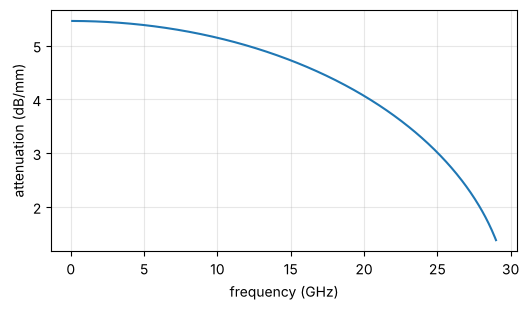

In [4]:
def neumann(n, h):
    main = np.full(n, 2.0); main[0] = main[-1] = 1.0
    return sps.diags([-np.ones(n - 1), main, -np.ones(n - 1)], [-1, 0, 1]) / h**2
na = 160; nb = int(round(na * b / a))
L = sps.kronsum(neumann(na, a / na), neumann(nb, b / nb), format='csc')
vals = np.sort(spla.eigsh(L, k=5, sigma=-1.0, which='LM', return_eigenvectors=False))[1:]
exact = [c0 / 2 * math.sqrt((m / a) ** 2 + (n / b) ** 2) for m, n in ((1, 0), (2, 0), (0, 1), (1, 1))]
for name, kc2, fe in zip(('TE10', 'TE20', 'TE01', 'TE11'), vals, exact):
    print(f"{name}: grid {math.sqrt(kc2) * c0 / (2 * math.pi) / 1e9:.4f} GHz, formula {fe / 1e9:.4f} GHz")
fs = np.linspace(0.1e9, 29e9, 400)
kc = math.pi / 0.005
alpha = np.sqrt(kc**2 - (2 * np.pi * fs / c0) ** 2)
print(f"5 mm tube at 2.4 GHz: {math.sqrt(kc**2 - (2 * math.pi * 2.4e9 / c0) ** 2) * 8.686 / 1000:.3f} dB per mm")
fig, ax = plt.subplots(figsize=(5.4, 3.2))
ax.plot(fs / 1e9, alpha * 8.686 / 1000); ax.set_xlabel('frequency (GHz)'); ax.set_ylabel('attenuation (dB/mm)'); ax.grid(alpha=0.3)
plt.tight_layout(); plt.show()

## Part 4 · The fibre's fundamental mode

For the fibre of Example 13-10.6 (core radius 4.1 µm, $n_1$ = 1.4504, $n_2$ = 1.4457), solve the LP$_{01}$ matching condition across wavelength, plot $b$ against V and the field at 1310 nm, and find V at 1260 nm.

**Predict first:** is the fibre single-mode at 1260 nm?

V at 1260 nm = 2.3853 (single-mode below 2.405); at 1310 nm V = 2.2943, b = 0.5029


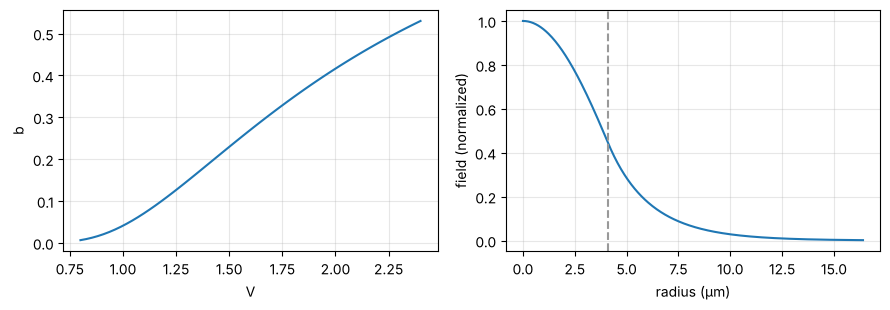

In [5]:
n1, n2, af = 1.4504, 1.4457, 4.1e-6
NA = math.sqrt(n1**2 - n2**2)
def solve(V):
    g = lambda u: u * jv(1, u) / jv(0, u) - math.sqrt(V * V - u * u) * kv(1, math.sqrt(V * V - u * u)) / kv(0, math.sqrt(V * V - u * u))
    u = brentq(g, 1e-6, min(V, 2.4048) - 1e-9); return u, math.sqrt(V * V - u * u)
Vs = np.linspace(0.8, 2.4, 60)
bs = [1 - solve(V)[0] ** 2 / V**2 for V in Vs]
V1310 = 2 * math.pi * af / 1.31e-6 * NA; u, w = solve(V1310)
r = np.linspace(0, 4 * af, 400)
E = np.where(r < af, jv(0, u * r / af) / jv(0, u), kv(0, w * np.maximum(r, 1e-12) / af) / kv(0, w))
print(f"V at 1260 nm = {2 * math.pi * af / 1.26e-6 * NA:.4f} (single-mode below 2.405); at 1310 nm V = {V1310:.4f}, b = {1 - u * u / V1310**2:.4f}")
fig, axes = plt.subplots(1, 2, figsize=(9, 3.2))
axes[0].plot(Vs, bs); axes[0].set_xlabel('V'); axes[0].set_ylabel('b'); axes[0].grid(alpha=0.3)
axes[1].plot(r * 1e6, E / E[0]); axes[1].axvline(af * 1e6, color='0.6', ls='--'); axes[1].set_xlabel('radius (µm)'); axes[1].set_ylabel('field (normalized)'); axes[1].grid(alpha=0.3)
plt.tight_layout(); plt.show()

## What to notice

- TE$_{10}$'s electric field peaks at the centre and vanishes at the side walls, as the tangential-E condition requires.
- Across WR-90's recommended band the group delay of 1 m varies by about 1.6 ns: waveguide is dispersive.
- A coarse grid already reproduces the cutoffs to a few parts in ten thousand; below cutoff, a 5 mm tube attenuates about 5.4 dB per millimetre at 2.4 GHz.
- At V = 2.39 (1260 nm) the fibre is just single-mode; the field spreads well into the cladding.